# Домашнее задание 8 — Базовые понятия статистики
**Дисциплина:** Программирование и аналитика на Python  
**Студент:** Белкин Григорий  
**Группа:** УЦП-25

**Источник:** материал «Базовые_Понятния.ipynb», данные [Horse Colic](https://raw.githubusercontent.com/obulygin/pyda_homeworks/master/statistics_basics/horse_data.csv), [описание 28 признаков](https://raw.githubusercontent.com/obulygin/pyda_homeworks/master/statistics_basics/horse_data.names).

Выполнена **обязательная часть, задания 1–3**, по восьми признакам. Дополнительная часть (анализ всех 28 полей) не входит в эту работу.

Для воспроизводимости приложен `horse_colic_selected_hw8.csv` — **восемь отобранных столбцов из исходного 300-строчного набора**, без изменения исходных значений (`?` — пропуск). Если этот файл отсутствует, ноутбук прочитает оригинальный CSV из GitHub (понадобится интернет).

## 0. Выбор признаков и подготовка

| № в исходном файле | Признак | Тип | Значение |
|---|---|---|---|
| 1 | `surgery` | категориальный | 1 — операция, 2 — без операции |
| 2 | `age` | категориальный | 1 — взрослая, **9 — молодая в данных** |
| 4 | `rectal_temp` | числовой | ректальная температура, °C |
| 5 | `pulse` | числовой | пульс, уд/мин |
| 6 | `respiratory_rate` | числовой | частота дыхания, движений/мин |
| 11 | `pain` | категориальный | степень боли, коды 1–5 (субъективный признак) |
| 19 | `packed_cell_volume` | числовой | гематокрит, % |
| 23 | `outcome` | категориальный | 1 — выжила, 2 — погибла, 3 — эвтаназия |

**Замечание по качеству данных:** в документации для молодой лошади указан код `2`, но в предоставленном датасете фактически встречается код `9`. Подменять его кодом 2 нельзя; при интерпретации используется значение 9. Коды категорий не рассматриваются как непрерывные числовые измерения.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

FEATURES = [
    'surgery', 'age', 'rectal_temp', 'pulse',
    'respiratory_rate', 'pain', 'packed_cell_volume', 'outcome'
]
NUMERIC = ['rectal_temp', 'pulse', 'respiratory_rate', 'packed_cell_volume']
CATEGORICAL = ['surgery', 'age', 'pain', 'outcome']
SOURCE_URL = 'https://raw.githubusercontent.com/obulygin/pyda_homeworks/master/statistics_basics/horse_data.csv'


def load_horse_data(local_path='horse_colic_selected_hw8.csv'):
    path = Path(local_path)
    if path.is_file():
        frame = pd.read_csv(path, na_values='?')
    else:
        usecols = [0, 1, 3, 4, 5, 10, 18, 22]
        frame = pd.read_csv(SOURCE_URL, header=None, usecols=usecols, na_values='?')
        frame.columns = FEATURES
    if list(frame.columns) != FEATURES:
        raise ValueError('Неожиданные названия или порядок столбцов')
    for col in FEATURES:
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    return frame


df_raw = load_horse_data()
print('Размер выборки:', df_raw.shape)
display(df_raw.head())

Размер выборки: (300, 8)


,surgery,age,rectal_temp,pulse,respiratory_rate,pain,packed_cell_volume,outcome
0,2.0,1,38.5,66.0,28.0,5.0,45.0,2.0
1,1.0,1,39.2,88.0,20.0,3.0,50.0,3.0
2,2.0,1,38.3,40.0,24.0,3.0,33.0,1.0
3,1.0,9,39.1,164.0,84.0,2.0,48.0,2.0
4,2.0,1,37.3,104.0,35.0,NaN,74.0,2.0


## 1. Базовое изучение и статистики

Числовые поля: количество наблюдений, среднее, медиана, мода, стандартное отклонение, минимум, максимум и квартильные значения. Категориальные: количество/доли каждого значения, мода и число разных категорий. Мода и медиана категориальных *кодов* не имеют единого количественного смысла, поэтому категории описываются частотами.

In [2]:
def numeric_statistics(frame, columns):
    desc = frame[columns].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    desc = desc.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'})
    desc['mode'] = [frame[col].mode(dropna=True).iloc[0] for col in columns]
    return desc[['count', 'mean', 'median', 'mode', 'std', 'min', 'Q1', 'Q3', 'max']].round(2)


def categorical_statistics(frame, columns):
    results = []
    for col in columns:
        values = frame[col]
        for value, count in values.value_counts(dropna=False).items():
            results.append({
                'field': col,
                'value': 'ПРОПУСК' if pd.isna(value) else str(int(value)),
                'count': int(count),
                'pct': round(100 * count / len(frame), 2),
            })
    return pd.DataFrame(results)

numeric_stats = numeric_statistics(df_raw, NUMERIC)
category_stats = categorical_statistics(df_raw, CATEGORICAL)
print('Числовые показатели:')
display(numeric_stats)
print('Категориальные показатели (включая пропуски):')
display(category_stats)

Числовые показатели:


,count,mean,median,mode,std,min,Q1,Q3,max
rectal_temp,240.0,38.17,38.2,38.0,0.73,35.4,37.8,38.5,40.8
pulse,276.0,71.91,64.0,48.0,28.63,30.0,48.0,88.0,184.0
respiratory_rate,242.0,30.42,24.5,20.0,17.64,8.0,18.5,36.0,96.0
packed_cell_volume,271.0,46.30,45.0,37.0,10.42,23.0,38.0,52.0,75.0


Категориальные показатели (включая пропуски):


,field,value,count,pct
0,surgery,1,180,60.00
1,surgery,2,119,39.67
2,surgery,ПРОПУСК,1,0.33
3,age,1,276,92.00
4,age,9,24,8.00
5,pain,3,67,22.33
6,pain,2,59,19.67
7,pain,ПРОПУСК,55,18.33
8,pain,5,42,14.00
9,pain,4,39,13.00


### Краткие выводы по исходному датасету

- **Температура:** медиана 38,2 °C, диапазон 35,4–40,8 °C. Есть как сниженные, так и повышенные значения; в описании указан ориентир нормы ~37,8 °C.
- **Пульс:** медиана 64 уд/мин, среднее 71,91; максимум 184. Среднее выше медианы: распределение имеет высокие значения, связанные, возможно, с болью/шоком.
- **Частота дыхания:** медиана 24,5, среднее 30,42; диапазон 8–96. По описанию признака показатель сильно меняется и интерпретировать его следует осторожно.
- **Гематокрит:** медиана 45 %, диапазон 23–75 %. Высокие значения могут соответствовать обезвоживанию/циркуляторным нарушениям.
- **Операция:** 180 случаев с операцией, 119 без неё, 1 неизвестный.
- **Возраст:** 276 взрослых (`1`), 24 молодых (`9`).
- **Боль:** самая частая отметка — `3` (67 случаев), при этом отсутствуют сведения в 55 строках; субъективные коды не трактуются как равномерная линейная шкала.
- **Исход:** 178 выживших, 77 погибших, 44 случая эвтаназии и 1 пропуск.

Эти выводы описывают *наблюдаемую выборку* и сами по себе не устанавливают причинных связей.

## 2. Работа с выбросами

Для **четырёх числовых** полей используем классическое правило IQR: значения за пределами `[Q1 − 1,5·IQR; Q3 + 1,5·IQR]` отмечаем как **статистические кандидаты в выбросы**, а не автоматически как ошибку. У категориальных полей выбросы методом IQR **не определяются**: проверяем допустимость их кодов.

In [3]:
def iqr_outliers(frame, column):
    s = frame[column].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = frame[column].notna() & ((frame[column] < low) | (frame[column] > high))
    return mask, {'column': column, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                  'lower': low, 'upper': high, 'n_outliers': int(mask.sum()),
                  'examples': sorted(frame.loc[mask, column].unique().tolist())}


def build_outlier_report(frame, columns):
    report = []
    masks = {}
    for col in columns:
        masks[col], info = iqr_outliers(frame, col)
        report.append(info)
    return pd.DataFrame(report), pd.DataFrame(masks)

outlier_report, outlier_flags = build_outlier_report(df_raw, NUMERIC)
display(outlier_report.round(2))

allowed_codes = {
    'surgery': {1, 2}, 'age': {1, 9},
    'pain': {1, 2, 3, 4, 5}, 'outcome': {1, 2, 3}
}
invalid_codes = {
    col: sorted(set(df_raw[col].dropna()) - codes)
    for col, codes in allowed_codes.items()
}
print('Недопустимые коды категорий:', invalid_codes)

,column,Q1,Q3,IQR,lower,upper,n_outliers,examples
0,rectal_temp,37.8,38.5,0.7,36.75,39.55,14,"[35.4, 36.0, 36.1, 36.4, 36.5, 36.6, 39.6, 39...."
1,pulse,48.0,88.0,40.0,-12.00,148.00,5,"[150.0, 160.0, 164.0, 184.0]"
2,respiratory_rate,18.5,36.0,17.5,-7.75,62.25,17,"[66.0, 68.0, 70.0, 72.0, 80.0, 84.0, 88.0, 90...."
3,packed_cell_volume,38.0,52.0,14.0,17.00,73.00,3,"[74.0, 75.0]"


Недопустимые коды категорий: {'surgery': [], 'age': [], 'pain': [], 'outcome': []}


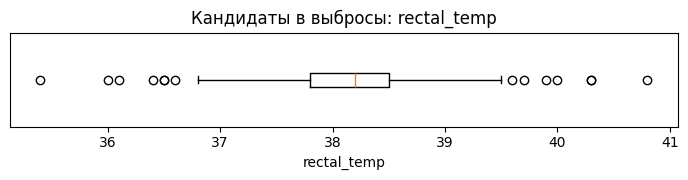

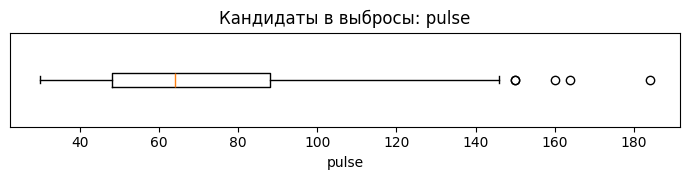

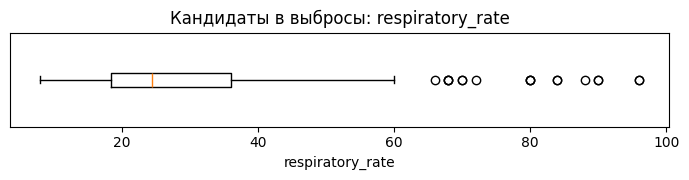

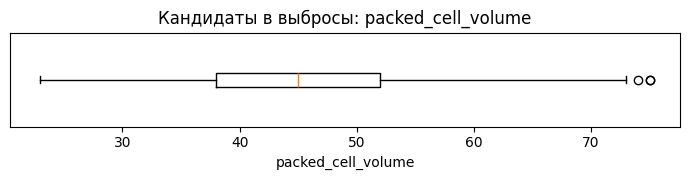

In [4]:
# Один boxplot на показатель: единицы измерения у столбцов различаются.
for col in NUMERIC:
    fig, ax = plt.subplots(figsize=(7, 1.9))
    ax.boxplot(df_raw[col].dropna(), vert=False, showfliers=True)
    ax.set_title(f'Кандидаты в выбросы: {col}')
    ax.set_xlabel(col)
    ax.set_yticks([])
    plt.tight_layout()
    plt.show()

### Интерпретация и решение по выбросам

| Числовой признак | Выбросов по IQR | Возможные причины | Решение |
|---|---:|---|---|
| Ректальная температура | **14** | Гипертермия при инфекции, гипотермия при тяжёлом шоке; возможны ошибки измерения | **Сохранить**, экстремальные показания проверить при наличии медицинской карты |
| Пульс | **5** | Тахикардия при боли, стрессе или циркуляторном шоке | **Сохранить**; максимум 184 уд/мин не считать ошибкой без доказательств |
| Частота дыхания | **17** | Боль, стресс, дыхательные или гемодинамические нарушения; субъективность/разброс измерений | **Сохранить**; не удалять автоматически |
| Гематокрит | **3** | Обезвоживание и гемоконцентрация | **Сохранить**, значения 74–75 % требуют клинической проверки |

По описанию исходного набора экстремумы клинически правдоподобны, и явных доказательств ошибки ввода нет. Поэтому **ни одна запись не удаляется и не подменяется**. Маски `outlier_flags` сохранены отдельно от аналитического датафрейма. Позднее при построении модели можно изучить устойчивые методы и анализ чувствительности. В категориальных полях проверяем **необычные/недопустимые коды**, а не вычисляем числовые IQR.

## 3. Работа с пропусками

Исходный файл использует символ `?` для пропусков, `read_csv` преобразует его в `NaN`. Подсчитаем **пропуски по всем восьми признакам** и отдельно укажем количество IQR-выбросов — в формулировке третьего пункта исходного ноутбука заголовок про пропуски, хотя в одной фразе повторно написано «количество выбросов». Проверяем оба показателя.

In [5]:
def completeness_report(frame, columns, numerical, outlier_table):
    outlier_counts = outlier_table.set_index('column')['n_outliers'].to_dict()
    return pd.DataFrame({
        'field': columns,
        'missing': [int(frame[c].isna().sum()) for c in columns],
        'missing_pct': [round(100 * frame[c].isna().mean(), 2) for c in columns],
        'IQR_outliers': [outlier_counts[c] if c in numerical else 'не применимо' for c in columns],
    })

missing_report = completeness_report(df_raw, FEATURES, NUMERIC, outlier_report)
display(missing_report)

,field,missing,missing_pct,IQR_outliers
0,surgery,1,0.33,не применимо
1,age,0,0.00,не применимо
2,rectal_temp,60,20.00,14
3,pulse,24,8.00,5
4,respiratory_rate,58,19.33,17
5,pain,55,18.33,не применимо
6,packed_cell_volume,29,9.67,3
7,outcome,1,0.33,не применимо


### Выбор методов обработки

- **`rectal_temp` (60/300):** заполнить медианой **38,2 °C**. Пропусков 20 %, удаление строк привело бы к существенной потере наблюдений, а медиана устойчива к экстремумам.
- **`pulse` (24/300):** медиана **64 уд/мин**; медиана лучше среднего при правостороннем хвосте.
- **`respiratory_rate` (58/300):** медиана **24,5**, округляем до **25 дыхательных движений/мин**, поскольку счёт дыхательных движений целочисленный.
- **`packed_cell_volume` (29/300):** медиана **45 %**, устойчивая к высоким экстремумам.
- **`surgery` (1/300):** отдельная категория `Неизвестно`; не делать вывод о наличии операции без данных.
- **`age` (0/300):** заполнять нечего; переводим коды `1` и `9` в метки.
- **`pain` (55/300):** отдельная категория `Неизвестно`, а не наиболее частая боль — иначе добавим ложную клиническую информацию.
- **`outcome` (1/300):** отдельная категория `Неизвестно`, чтобы не приписать пациенту выживание/гибель.

Это решение подходит **для учебного описательного анализа**, но восстановленные показатели не являются настоящими измерениями. При клиническом исследовании или машинном обучении методы обработки пропусков стоит выбирать с учётом механизма их появления и проверять влияние на выводы.

In [6]:
def fill_missing_values(frame, numeric_cols, categorical_cols, codes):
    cleaned = frame.copy(deep=True)
    for col in numeric_cols:
        median = cleaned[col].median()
        if col in {'pulse', 'respiratory_rate'}:
            median = int(np.floor(median + 0.5))  # счёт движений/ударов целочисленный
        cleaned[col] = cleaned[col].fillna(median)
    for col in categorical_cols:
        cleaned[col] = cleaned[col].map(codes[col]).fillna('Неизвестно')
    return cleaned

labels = {
    'surgery': {1: 'Операция', 2: 'Без операции'},
    'age': {1: 'Взрослая', 9: 'Молодая'},
    'pain': {1: 'Нет боли', 2: 'Подавленное состояние', 3: 'Слабая периодическая боль',
             4: 'Сильная периодическая боль', 5: 'Сильная непрерывная боль'},
    'outcome': {1: 'Выжила', 2: 'Погибла', 3: 'Эвтаназия'}
}

df_clean = fill_missing_values(df_raw, NUMERIC, CATEGORICAL, labels)
assert df_clean.shape == (300, 8)
assert not df_clean.isna().any().any(), 'После обработки остались пропуски!'

print('Размер обработанного датафрейма:', df_clean.shape)
print('Пропусков после обработки:', int(df_clean.isna().sum().sum()))
display(df_clean.head(10))

Размер обработанного датафрейма: (300, 8)
Пропусков после обработки: 0


,surgery,age,rectal_temp,pulse,respiratory_rate,pain,packed_cell_volume,outcome
0,Без операции,Взрослая,38.5,66.0,28.0,Сильная непрерывная боль,45.0,Погибла
1,Операция,Взрослая,39.2,88.0,20.0,Слабая периодическая боль,50.0,Эвтаназия
2,Без операции,Взрослая,38.3,40.0,24.0,Слабая периодическая боль,33.0,Выжила
3,Операция,Молодая,39.1,164.0,84.0,Подавленное состояние,48.0,Погибла
4,Без операции,Взрослая,37.3,104.0,35.0,Неизвестно,74.0,Погибла
5,Без операции,Взрослая,38.2,64.0,25.0,Подавленное состояние,45.0,Выжила
6,Операция,Взрослая,37.9,48.0,16.0,Слабая периодическая боль,37.0,Выжила
7,Операция,Взрослая,38.2,60.0,25.0,Неизвестно,44.0,Погибла
8,Без операции,Взрослая,38.2,80.0,36.0,Сильная периодическая боль,38.0,Эвтаназия
9,Без операции,Молодая,38.3,90.0,25.0,Сильная непрерывная боль,40.0,Выжила


In [7]:
# Выходной файл содержит восемь выбранных полей; исходный CSV не изменяется.
output_file = 'horse_colic_cleaned_hw8.csv'
df_clean.to_csv(output_file, index=False, encoding='utf-8-sig')
print('Сохранено:', output_file)

# Контроль: 300 наблюдений до и после, пропуски отсутствуют,
# выбросы не удалены и сохранили исходные значения.
assert len(df_clean) == len(df_raw) == 300
for col in NUMERIC:
    assert df_clean.loc[df_raw[col].notna(), col].equals(df_raw.loc[df_raw[col].notna(), col])
print('Проверка исходных ненулевых измерений: OK')

Сохранено: horse_colic_cleaned_hw8.csv
Проверка исходных ненулевых измерений: OK


## Итог

1. Из 28 атрибутов исходного набора выбраны 8: **4 числовых + 4 категориальных**; рассчитаны описательные статистики и частоты.
2. По правилу 1,5 IQR найдено **14 / 5 / 17 / 3** кандидатов в выбросы соответственно для температуры / пульса / дыхания / гематокрита. Они сохранены, поскольку в медицинских данных могут быть информативными.
3. Подсчитаны пропуски во всех 8 столбцах; медианами восстановлены числовые признаки, категориальные пропуски явно отмечены `Неизвестно`. Получен датафрейм **300 × 8** без `NaN`; проверяется неизменность всех исходно известных числовых измерений.
